In [1]:
import os

def build_dataset(root_path, subjects):
    data_list = []

    for subject in subjects:
        ct_path = os.path.join(root_path, subject, "CT")
        uct_path = os.path.join(root_path, subject, "UCT")

        ct_file = None
        mask_file = None

        # find files
        for f in os.listdir(ct_path):
            if "CT_RAW" in f:
                ct_file = os.path.join(ct_path, f)

        for f in os.listdir(uct_path):
            if f.endswith("_LABELS.nii"):
                mask_file = os.path.join(uct_path, f)

        if ct_file and mask_file:
            data_list.append({
                "subject": subject,
                "ct": ct_file,
                "mask": mask_file
            })

    return data_list

In [2]:
train_subjects = [f"F{i:02d}" for i in range(1, 11)] + [f"T{i:02d}" for i in range(1, 6)]

val_subjects = [f"F{i:02d}" for i in range(11, 14)]

test_subjects = [f"F{i:02d}" for i in range(14, 16)] + [f"T{i:02d}" for i in range(6, 9)]

In [3]:
root = "DATASET_ROOT"

train_data = build_dataset(root, train_subjects)
val_data = build_dataset(root, val_subjects)
test_data = build_dataset(root, test_subjects)

print("Train:", len(train_data))
print("Val:", len(val_data))
print("Test:", len(test_data))

Train: 15
Val: 3
Test: 5


In [4]:
import torch
from torch.utils.data import Dataset
import nibabel as nib
import numpy as np
import torch.nn.functional as F

class CTDataset2D(Dataset):
    def __init__(self, data_list, size=(128, 128), min_mask_sum=50):
        self.size = size
        self.samples = []

        for item in data_list:
            ct = nib.load(item["ct"]).get_fdata()
            mask = nib.load(item["mask"]).get_fdata()

            depth = ct.shape[2]

            for i in range(depth):

                m = mask[:, :, i]

                #  FILTER: skip empty slices
                if m.sum() < min_mask_sum:
                    continue

                self.samples.append((item, i))

    def __len__(self):
        return len(self.samples)

    def normalize(self, img):
        img = img.astype(np.float32)
        return (img - img.mean()) / (img.std() + 1e-8)

    def resize(self, img, is_mask=False):
        img = torch.tensor(img, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

        mode = "nearest" if is_mask else "bilinear"

        img = F.interpolate(
            img,
            size=self.size,
            mode=mode,
            align_corners=False if not is_mask else None
        )

        return img.squeeze(0).squeeze(0)

    def __getitem__(self, idx):
        item, i = self.samples[idx]

        ct = nib.load(item["ct"]).get_fdata()
        mask = nib.load(item["mask"]).get_fdata()

        depth = ct.shape[2]

        # 3 adjacent slices
        i0 = max(i - 1, 0)
        i1 = i
        i2 = min(i + 1, depth - 1)

        s0 = self.resize(self.normalize(ct[:, :, i0]), is_mask=False)
        s1 = self.resize(self.normalize(ct[:, :, i1]), is_mask=False)
        s2 = self.resize(self.normalize(ct[:, :, i2]), is_mask=False)

        # STACK → (3, H, W)
        ct_tensor = torch.stack([s0, s1, s2], dim=0)

        mask_slice = self.resize(mask[:, :, i], is_mask=True)
        mask_tensor = (mask_slice > 0.5).float().unsqueeze(0)

        return ct_tensor, mask_tensor

C:\Users\Mohamed\anaconda3\lib\site-packages\numpy\_distributor_init.py:30: UserWarning: loaded more than 1 DLL from .libs:
C:\Users\Mohamed\anaconda3\lib\site-packages\numpy\.libs\libopenblas.XWYDX2IKJW2NMTWSFYNGFUWKQU3LYTCZ.gfortran-win_amd64.dll
C:\Users\Mohamed\anaconda3\lib\site-packages\numpy\.libs\libopenblas64__v0.3.21-gcc_10_3_0.dll
  warnings.warn("loaded more than 1 DLL from .libs:"


In [5]:
import SimpleITK as sitk
import os

def preprocess_subject(ct_path, mask_path, out_mask_path):
    ct = sitk.ReadImage(ct_path)
    mask = sitk.ReadImage(mask_path)

    resampler = sitk.ResampleImageFilter()
    resampler.SetReferenceImage(ct)
    resampler.SetInterpolator(sitk.sitkNearestNeighbor)

    mask_aligned = resampler.Execute(mask)

    sitk.WriteImage(mask_aligned, out_mask_path)


for item in train_data + val_data + test_data:
    ct_path = item["ct"]
    mask_path = item["mask"]

    out_mask = mask_path.replace(".nii", "_aligned.nii")

    preprocess_subject(ct_path, mask_path, out_mask)

    item["mask"] = out_mask

In [6]:
from torch.utils.data import DataLoader

train_dataset = CTDataset2D(train_data)
val_dataset = CTDataset2D(val_data)
test_dataset = CTDataset2D(test_data)


train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)


print("Train samples:", len(train_dataset))

Train samples: 1108


In [7]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNetSmall(nn.Module):
    def __init__(self):
        super().__init__()
        self.down1 = DoubleConv(3, 32)   
        self.pool = nn.MaxPool2d(2)
        self.down2 = DoubleConv(32, 64)
        self.down3 = DoubleConv(64, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.conv1 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.conv2 = DoubleConv(64, 32)

        self.out = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        x1 = self.down1(x)
        x2 = self.pool(x1)
        x3 = self.down2(x2)
        x4 = self.pool(x3)
        x5 = self.down3(x4)

        x = self.up1(x5)
        x = torch.cat([x, x3], dim=1)
        x = self.conv1(x)

        x = self.up2(x)
        x = torch.cat([x, x1], dim=1)
        x = self.conv2(x)

        return self.out(x)  # no sigmoid here

In [8]:
# import torch
# import torch.nn as nn


# class DiceBCELoss(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.bce = nn.BCEWithLogitsLoss()

#     def forward(self, logits, target, eps=1e-6):

#         probs = torch.sigmoid(logits)

#         bce = self.bce(logits, target)

#         intersection = (probs * target).sum(dim=(1,2,3))
#         union = probs.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3))

#         dice = (2 * intersection + eps) / (union + eps)

#         dice_loss = 1 - dice.mean()

#         return bce + dice_loss
    
# device = "cuda" if torch.cuda.is_available() else "cpu"

# model = UNetSmall().to(device)
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
# criterion = DiceBCELoss()

# for epoch in range(25):

#     model.train()
#     total_loss = 0

#     for ct, mask in train_loader:

#         ct = ct.to(device)
#         mask = mask.to(device)

#         logits = model(ct)
#         loss = criterion(logits, mask)

#         optimizer.zero_grad()
#         loss.backward()
#         optimizer.step()

#         total_loss += loss.item()

#     print(f"Epoch {epoch}: Loss = {total_loss/len(train_loader):.4f}")    

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = UNetSmall().to(device)
model.load_state_dict(torch.load("unet_final.pth", map_location=device))
model.eval()

UNetSmall(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (down3): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (up1): ConvTranspose2d(128, 64, kernel_size=(2, 2), stride=(2, 2))
  (conv1): DoubleCon

In [10]:
def dice(pred, target, eps=1e-6):
    pred = (pred > 0.5).float()
    target = target.float()

    intersection = (pred * target).sum()
    return (2. * intersection + eps) / (pred.sum() + target.sum() + eps)

In [11]:
model.eval()
scores = []

with torch.no_grad():
    for ct, mask in val_loader:
        ct = ct.to(device)
        mask = mask.to(device)

        pred = model(ct)

        scores.append(dice(pred, mask).item())

print("Dice score:", sum(scores)/len(scores))

Dice score: 0.7747709545595892


In [12]:
model.eval()
test_scores = []

with torch.no_grad():
    for ct, mask in test_loader:
        ct = ct.to(device)
        mask = mask.to(device)

        logits = model(ct)
        probs = torch.sigmoid(logits)

        test_scores.append(dice(probs, mask).item())

print("Test Dice:", sum(test_scores) / len(test_scores))

Test Dice: 0.7563155929247538


In [13]:
with torch.no_grad():
    logits = model(ct)
    probs = torch.sigmoid(logits)

pred = (probs > 0.5).cpu().numpy()

# CLEAN STEP
import scipy.ndimage as nd

labeled, num = nd.label(pred)
clean = np.zeros_like(pred)

for i in range(1, num+1):
    component = (labeled == i)
    if component.sum() > 50:
        clean[component] = 1

In [14]:
import os
import json
import numpy as np
import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from nibabel.affines import apply_affine

# ============================================================
# CONFIG
# ============================================================
ROOT = "DATASET_ROOT"

TRAIN_SUBJECTS = [f"F{i:02d}" for i in range(1, 11)] + [f"T{i:02d}" for i in range(1, 6)]
VAL_SUBJECTS   = [f"F{i:02d}" for i in range(11, 14)]
TEST_SUBJECTS  = [f"F{i:02d}" for i in range(14, 16)] + [f"T{i:02d}" for i in range(6, 9)]

LANDMARK_NAMES = ["RW", "C", "A", "OW", "V"]

# Network input/output size in (D, H, W)
# Keep these divisible by 4 because we use 2 pooling layers
TARGET_SHAPE = (96, 128, 128)

SIGMA = 2.5
BATCH_SIZE = 1
EPOCHS = 40
LR = 1e-4

device = "cuda" if torch.cuda.is_available() else "cpu"


# ============================================================
# DATA DISCOVERY
# ============================================================
def build_dataset(root_path, subjects):
    data_list = []

    for subject in subjects:
        subject_path = os.path.join(root_path, subject)
        ct_path = os.path.join(subject_path, "CT")

        ct_file = None
        desc_file = None

        if os.path.isdir(ct_path):
            for f in os.listdir(ct_path):
                if "CT_RAW" in f and f.endswith(".nii"):
                    ct_file = os.path.join(ct_path, f)
                    break

        if os.path.isdir(subject_path):
            for f in os.listdir(subject_path):
                if f.endswith("_DESC.json"):
                    desc_file = os.path.join(subject_path, f)
                    break

        if ct_file and desc_file:
            data_list.append({
                "subject": subject,
                "ct": ct_file,
                "desc": desc_file
            })

    return data_list


train_data = build_dataset(ROOT, TRAIN_SUBJECTS)
val_data   = build_dataset(ROOT, VAL_SUBJECTS)
test_data  = build_dataset(ROOT, TEST_SUBJECTS)

print("Train:", len(train_data))
print("Val:", len(val_data))
print("Test:", len(test_data))


# ============================================================
# DESC LOADING
# ============================================================
def load_desc(desc_path):
    with open(desc_path, "r") as f:
        data = json.load(f)

    landmarks = {
        k: np.asarray(v, dtype=np.float32)
        for k, v in data["LANDMARKS"].items()
    }

    return {
        "id": data.get("ID", ""),
        "side": data.get("SIDE", ""),
        "landmarks": landmarks,
        "origin": np.asarray(data["COORD"]["ORIGIN"], dtype=np.float32),
        "xaxis": np.asarray(data["COORD"]["XAXIS"], dtype=np.float32),
        "yaxis": np.asarray(data["COORD"]["YAXIS"], dtype=np.float32),
        "zaxis": np.asarray(data["COORD"]["ZAXIS"], dtype=np.float32),
    }


# ============================================================
# HELPERS
# ============================================================
def normalize_volume(vol):
    vol = vol.astype(np.float32)
    return (vol - vol.mean()) / (vol.std() + 1e-8)


def world_to_voxel(world_coord, affine):
    inv_affine = np.linalg.inv(affine)
    return apply_affine(inv_affine, world_coord)


def voxel_xyz_to_net(v_xyz):
    # CT array is (X, Y, Z)
    # network uses (D, H, W) = (Z, X, Y)
    x, y, z = v_xyz
    return np.array([z, x, y], dtype=np.float32)


def net_to_voxel_xyz(v_net):
    # (D, H, W) -> (X, Y, Z)
    d, h, w = v_net
    return np.array([h, w, d], dtype=np.float32)


def resize_volume_3d(vol, target_shape):
    """
    vol: numpy array with shape (D, H, W)
    returns torch tensor with shape (1, D, H, W)
    """
    t = torch.tensor(vol, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    t = F.interpolate(t, size=target_shape, mode="trilinear", align_corners=False)
    return t.squeeze(0)


def resize_heatmap_3d(hm, target_shape):
    """
    hm: numpy array with shape (D, H, W)
    returns torch tensor with shape (D, H, W)
    """
    t = torch.tensor(hm, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    t = F.interpolate(t, size=target_shape, mode="trilinear", align_corners=False)
    return t.squeeze(0).squeeze(0)


def make_gaussian_3d(shape, center, sigma=2.5):
    """
    shape: (D, H, W)
    center: (d, h, w)
    """
    D, H, W = shape
    dz = np.arange(D, dtype=np.float32)[:, None, None]
    dy = np.arange(H, dtype=np.float32)[None, :, None]
    dx = np.arange(W, dtype=np.float32)[None, None, :]

    cd, ch, cw = center
    dist2 = (dz - cd) ** 2 + (dy - ch) ** 2 + (dx - cw) ** 2
    hm = np.exp(-dist2 / (2 * sigma ** 2)).astype(np.float32)
    return hm


def decode_heatmap_argmax(hm):
    """
    hm: torch tensor or numpy array with shape (D, H, W)
    returns (d, h, w)
    """
    if torch.is_tensor(hm):
        idx = torch.argmax(hm).item()
        D, H, W = hm.shape
    else:
        idx = int(np.argmax(hm))
        D, H, W = hm.shape

    d = idx // (H * W)
    rem = idx % (H * W)
    h = rem // W
    w = rem % W
    return np.array([d, h, w], dtype=np.float32)


# ============================================================
# DATASET
# ============================================================
class LandmarkDataset(Dataset):
    def __init__(self, data_list, landmark_names, target_shape=(96, 128, 128), sigma=2.5):
        self.data_list = data_list
        self.landmark_names = landmark_names
        self.target_shape = target_shape
        self.sigma = sigma

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, idx):
        item = self.data_list[idx]

        ct_img = nib.load(item["ct"])
        ct = ct_img.get_fdata().astype(np.float32)
        affine = ct_img.affine

        # Original CT shape is (X, Y, Z)
        orig_shape_xyz = np.array(ct.shape, dtype=np.float32)

        # Convert to network order: (D, H, W) = (Z, X, Y)
        ct_net = np.transpose(ct, (2, 0, 1))
        ct_net = normalize_volume(ct_net)

        # Resize CT
        ct_resized = resize_volume_3d(ct_net, self.target_shape)

        # Build heatmaps
        desc = load_desc(item["desc"])
        heatmaps = []

        for name in self.landmark_names:
            world = desc["landmarks"][name]
            voxel_xyz = world_to_voxel(world, affine)
            voxel_net = voxel_xyz_to_net(voxel_xyz)

            # Scale voxel coords from original net shape -> target shape
            orig_net_shape = np.array([ct.shape[2], ct.shape[0], ct.shape[1]], dtype=np.float32)
            scale = (np.array(self.target_shape, dtype=np.float32) - 1.0) / (orig_net_shape - 1.0 + 1e-8)
            center = voxel_net * scale

            hm = make_gaussian_3d(self.target_shape, center=center, sigma=self.sigma)
            heatmaps.append(hm)

        heatmaps = np.stack(heatmaps, axis=0)  # (L, D, H, W)
        heatmaps = torch.tensor(heatmaps, dtype=torch.float32)

        return ct_resized, heatmaps, item["subject"], affine, ct.shape


# ============================================================
# MODEL
# ============================================================
class DoubleConv3D(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_c, out_c, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_c, out_c, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_c),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet3D(nn.Module):
    def __init__(self, in_channels=1, out_channels=5, base=16):
        super().__init__()
        self.enc1 = DoubleConv3D(in_channels, base)
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = DoubleConv3D(base, base * 2)
        self.pool2 = nn.MaxPool3d(2)

        self.bottleneck = DoubleConv3D(base * 2, base * 4)

        self.up2 = nn.ConvTranspose3d(base * 4, base * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv3D(base * 4, base * 2)

        self.up1 = nn.ConvTranspose3d(base * 2, base, kernel_size=2, stride=2)
        self.dec1 = DoubleConv3D(base * 2, base)

        self.out = nn.Conv3d(base, out_channels, kernel_size=1)

    def forward(self, x):
        x1 = self.enc1(x)
        x2 = self.pool1(x1)

        x3 = self.enc2(x2)
        x4 = self.pool2(x3)

        x5 = self.bottleneck(x4)

        x = self.up2(x5)
        x = torch.cat([x, x3], dim=1)
        x = self.dec2(x)

        x = self.up1(x)
        x = torch.cat([x, x1], dim=1)
        x = self.dec1(x)

        return self.out(x)


# ============================================================
# LOSS
# ============================================================
criterion = nn.MSELoss()

def landmark_distance_mm(pred_world, gt_world):
    return float(np.linalg.norm(pred_world - gt_world))


# ============================================================
# TRAIN / VAL
# ============================================================
train_dataset = LandmarkDataset(train_data, LANDMARK_NAMES, TARGET_SHAPE, SIGMA)
val_dataset   = LandmarkDataset(val_data, LANDMARK_NAMES, TARGET_SHAPE, SIGMA)
test_dataset  = LandmarkDataset(test_data, LANDMARK_NAMES, TARGET_SHAPE, SIGMA)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=1, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=1, shuffle=False)

model = UNet3D(in_channels=1, out_channels=len(LANDMARK_NAMES), base=16).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

best_val = 1e9
best_path = "best_landmark_model.pth"

# for epoch in range(EPOCHS):
#     model.train()
#     running = 0.0

#     for ct, heatmaps, _, _, _ in train_loader:
#         ct = ct.to(device)                  # (B, 1, D, H, W)
#         heatmaps = heatmaps.to(device)      # (B, L, D, H, W)

#         pred = model(ct)
#         loss = criterion(pred, heatmaps)

#         optimizer.zero_grad()
#         loss.backward()
#         optimizer.step()

#         running += loss.item()

#     train_loss = running / len(train_loader)

#     model.eval()
#     val_running = 0.0
#     with torch.no_grad():
#         for ct, heatmaps, _, _, _ in val_loader:
#             ct = ct.to(device)
#             heatmaps = heatmaps.to(device)
#             pred = model(ct)
#             loss = criterion(pred, heatmaps)
#             val_running += loss.item()

#     val_loss = val_running / len(val_loader)

#     print(f"Epoch {epoch+1:03d} | train loss: {train_loss:.5f} | val loss: {val_loss:.5f}")

#     if val_loss < best_val:
#         best_val = val_loss
#         torch.save(model.state_dict(), best_path)

# print("Best val loss:", best_val)


# ============================================================
# INFERENCE
# ============================================================
def predict_landmarks(model, ct_path, desc_path=None, target_shape=TARGET_SHAPE):
    ct_img = nib.load(ct_path)
    ct = ct_img.get_fdata().astype(np.float32)
    affine = ct_img.affine

    ct_net = np.transpose(ct, (2, 0, 1))
    ct_net = normalize_volume(ct_net)
    ct_tensor = resize_volume_3d(ct_net, target_shape).unsqueeze(0).to(device)  # (1,1,D,H,W)

    model.eval()
    with torch.no_grad():
        pred_hm = model(ct_tensor)[0].cpu()  # (L, D, H, W)

    pred_world = {}
    pred_vox = {}

    orig_net_shape = np.array([ct.shape[2], ct.shape[0], ct.shape[1]], dtype=np.float32)
    scale_back = (orig_net_shape - 1.0) / (np.array(target_shape, dtype=np.float32) - 1.0 + 1e-8)

    for i, name in enumerate(LANDMARK_NAMES):
        hm = pred_hm[i]
        coord_net = decode_heatmap_argmax(hm)   # in target net space

        # back to original net space
        coord_net_orig = coord_net * scale_back

        # back to original voxel xyz
        coord_xyz = net_to_voxel_xyz(coord_net_orig)
        pred_vox[name] = coord_xyz

        # to world
        world = apply_affine(affine, coord_xyz)
        pred_world[name] = world

    gt_world = None
    if desc_path is not None:
        desc = load_desc(desc_path)
        gt_world = desc["landmarks"]

    return pred_world, pred_vox, gt_world, pred_hm


# ============================================================
# EVALUATION
# ============================================================
def evaluate_split(data_list, model):
    all_errors = {name: [] for name in LANDMARK_NAMES}
    mean_errors = []

    for item in data_list:
        pred_world, _, gt_world, _ = predict_landmarks(model, item["ct"], item["desc"])

        subj_errors = []
        for name in LANDMARK_NAMES:
            err = landmark_distance_mm(pred_world[name], gt_world[name])
            all_errors[name].append(err)
            subj_errors.append(err)

        mean_errors.append(np.mean(subj_errors))

        print(f"\nSubject {item['subject']}")
        for name in LANDMARK_NAMES:
            print(f"  {name}: {all_errors[name][-1]:.2f} mm")

    print("\n================ SUMMARY ================")
    for name in LANDMARK_NAMES:
        print(f"{name}: mean error = {np.mean(all_errors[name]):.2f} mm")

    print(f"Overall mean landmark error = {np.mean(mean_errors):.2f} mm")


# # ============================================================
# # LOAD BEST MODEL AND TEST
# # ============================================================
# model.load_state_dict(torch.load(best_path, map_location=device))
# model.to(device)

# evaluate_split(test_data, model)

Train: 15
Val: 3
Test: 5


In [16]:
# device = "cuda" if torch.cuda.is_available() else "cpu"

# model = UNet3D(in_channels=1, out_channels=5, base=16).to(device)
# #model.load_state_dict(torch.load("unet3d_final.pth", map_location=device))
# model.load_state_dict(torch.load("unet_final.pth", map_location=device))

# model.eval()

In [17]:
# ============================================================
# EVALUATION
# ============================================================
def evaluate_split(data_list, model):
    all_errors = {name: [] for name in LANDMARK_NAMES}
    mean_errors = []

    for item in data_list:
        pred_world, _, gt_world, _ = predict_landmarks(model, item["ct"], item["desc"])

        subj_errors = []
        for name in LANDMARK_NAMES:
            err = landmark_distance_mm(pred_world[name], gt_world[name])
            all_errors[name].append(err)
            subj_errors.append(err)

        mean_errors.append(np.mean(subj_errors))

        print(f"\nSubject {item['subject']}")
        for name in LANDMARK_NAMES:
            print(f"  {name}: {all_errors[name][-1]:.2f} mm")

    print("\n================ SUMMARY ================")
    for name in LANDMARK_NAMES:
        print(f"{name}: mean error = {np.mean(all_errors[name]):.2f} mm")

    print(f"Overall mean landmark error = {np.mean(mean_errors):.2f} mm")


# ============================================================
# LOAD BEST MODEL AND TEST
# ============================================================
model.load_state_dict(torch.load(best_path, map_location=device))
model.to(device)

evaluate_split(test_data, model)


Subject F14
  RW: 3.42 mm
  C: 5.05 mm
  A: 4.92 mm
  OW: 4.60 mm
  V: 6.12 mm

Subject F15
  RW: 9.52 mm
  C: 9.28 mm
  A: 9.34 mm
  OW: 4.33 mm
  V: 7.72 mm

Subject T06
  RW: 5.22 mm
  C: 3.90 mm
  A: 5.66 mm
  OW: 3.18 mm
  V: 5.26 mm

Subject T07
  RW: 4.10 mm
  C: 4.20 mm
  A: 6.24 mm
  OW: 4.49 mm
  V: 6.30 mm

Subject T08
  RW: 4.80 mm
  C: 6.70 mm
  A: 3.41 mm
  OW: 4.86 mm
  V: 5.99 mm

================ SUMMARY ================
RW: mean error = 5.41 mm
C: mean error = 5.83 mm
A: mean error = 5.91 mm
OW: mean error = 4.29 mm
V: mean error = 6.28 mm
Overall mean landmark error = 5.54 mm


In [49]:
import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import nibabel as nib
import matplotlib.pyplot as plt
import scipy.ndimage as nd

from nibabel.affines import apply_affine
from matplotlib.backends.backend_pdf import PdfPages
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple

try:
    from skimage.measure import marching_cubes
except:
    from skimage.measure import marching_cubes_lewiner as marching_cubes

# ============================================================
# CONFIG
# ============================================================
DATASET_NAME = "CT/UCT surgical landmark dataset with DESC annotations"
REPORT_DIR = "reports"
os.makedirs(REPORT_DIR, exist_ok=True)

LANDMARK_NAMES = ["RW", "C", "A", "OW", "V"]

# Landmarks used for the final summary error in the report
# Keep all 5 visible, but compute the summary error using these 3.
SUMMARY_LANDMARKS = ["RW", "C", "OW"]

TARGET_SHAPE = (96, 128, 128)   # (D, H, W) for the landmark model
SEG_INPUT_SIZE = (128, 128)     # for 2.5D segmentation model

RISK_FEATURES = [
    "dist_C_RW",
    "dist_C_OW",
    "dist_RW_OW",
    "landmark_span",
    "compactness",
    "num_components",
]

device = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# DATA LOADER
# ============================================================
# ============================================================
# CONFIG
# ============================================================
DATASET_NAME = "CT/UCT surgical landmark dataset with DESC annotations"
REPORT_DIR = "reports"
os.makedirs(REPORT_DIR, exist_ok=True)

LANDMARK_NAMES = ["RW", "C", "A", "OW", "V"]
SUMMARY_LANDMARKS = ["RW", "C", "OW"]

TARGET_SHAPE = (96, 128, 128)
SEG_INPUT_SIZE = (128, 128)

RISK_FEATURES = [
    "dist_C_RW",
    "dist_C_OW",
    "dist_RW_OW",
    "landmark_span",
    "compactness",
    "num_components",
]

device = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# FILE HELPERS
# ============================================================
def find_first_file(folder, includes=None, suffixes=None):
    if not os.path.isdir(folder):
        return None

    includes = includes or []
    suffixes = suffixes or []

    for f in os.listdir(folder):
        low = f.lower()
        ok_inc = all(s.lower() in low for s in includes)
        ok_suf = any(low.endswith(s.lower()) for s in suffixes) if suffixes else True
        if ok_inc and ok_suf:
            return os.path.join(folder, f)
    return None

def find_mask_file(subject_path):
    candidates = [
        os.path.join(subject_path, "UCT"),
        os.path.join(subject_path, "CT"),
        subject_path,
    ]

    for folder in candidates:
        if not os.path.isdir(folder):
            continue

        hit = find_first_file(folder, includes=["labels"], suffixes=[".nii", ".nii.gz"])
        if hit:
            return hit

        hit = find_first_file(folder, includes=["mask"], suffixes=[".nii", ".nii.gz"])
        if hit:
            return hit

        hit = find_first_file(folder, includes=["seg"], suffixes=[".nii", ".nii.gz"])
        if hit:
            return hit

    for root, _, files in os.walk(subject_path):
        for f in files:
            low = f.lower()
            if ("labels" in low or "mask" in low or "seg" in low) and (
                low.endswith(".nii") or low.endswith(".nii.gz")
            ):
                return os.path.join(root, f)

    return None

# ============================================================
# DATA LOADER
# ============================================================
def build_dataset(root_path, subjects):
    data_list = []

    for subject in subjects:
        subject_path = os.path.join(root_path, subject)
        ct_path = os.path.join(subject_path, "CT")
        uct_path = os.path.join(subject_path, "UCT")

        ct_file = None
        mask_file = None
        desc_file = None

        if os.path.isdir(ct_path):
            for f in os.listdir(ct_path):
                low = f.lower()
                if "ct_raw" in low and (low.endswith(".nii") or low.endswith(".nii.gz")):
                    ct_file = os.path.join(ct_path, f)
                    break

        if os.path.isdir(uct_path):
            for f in os.listdir(uct_path):
                low = f.lower()
                if ("labels_aligned" in low or "mask_aligned" in low) and (
                    low.endswith(".nii") or low.endswith(".nii.gz")
                ):
                    mask_file = os.path.join(uct_path, f)
                    break

            if mask_file is None:
                for f in os.listdir(uct_path):
                    low = f.lower()
                    if ("labels" in low or "mask" in low) and (
                        low.endswith(".nii") or low.endswith(".nii.gz")
                    ):
                        mask_file = os.path.join(uct_path, f)
                        break

        if os.path.isdir(subject_path):
            for f in os.listdir(subject_path):
                if f.endswith("_DESC.json"):
                    desc_file = os.path.join(subject_path, f)
                    break

        if ct_file and desc_file:
            data_list.append({
                "subject": subject,
                "ct": ct_file,
                "mask": mask_file,
                "desc": desc_file
            })

    return data_list

# ============================================================
# DESC LOADING
# ============================================================
def normalize_vec(v):
    v = np.asarray(v, dtype=np.float32)
    n = np.linalg.norm(v) + 1e-8
    return v / n

def load_desc(desc_path):
    with open(desc_path, "r") as f:
        data = json.load(f)

    landmarks = {
        k: np.asarray(v, dtype=np.float32)
        for k, v in data["LANDMARKS"].items()
    }

    return {
        "id": data.get("ID", ""),
        "side": data.get("SIDE", ""),
        "landmarks": landmarks,
        "origin": np.asarray(data["COORD"]["ORIGIN"], dtype=np.float32),
        "xaxis": normalize_vec(data["COORD"]["XAXIS"]),
        "yaxis": normalize_vec(data["COORD"]["YAXIS"]),
        "zaxis": normalize_vec(data["COORD"]["ZAXIS"]),
    }

# ============================================================
# BASIC HELPERS
# ============================================================
def fmt(v, ndigits=3):
    try:
        if np.isnan(v):
            return "NaN"
    except Exception:
        pass
    if isinstance(v, (float, np.floating)):
        return f"{v:.{ndigits}f}"
    return str(v)

def normalize_volume(vol):
    vol = vol.astype(np.float32)
    return (vol - vol.mean()) / (vol.std() + 1e-8)

def resize_3d_np(vol, target_shape):
    t = torch.tensor(vol, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    t = F.interpolate(t, size=target_shape, mode="trilinear", align_corners=False)
    return t.squeeze(0).squeeze(0)

def decode_heatmap_argmax(hm):
    idx = torch.argmax(hm).item()
    D, H, W = hm.shape
    d = idx // (H * W)
    rem = idx % (H * W)
    h = rem // W
    w = rem % W
    return np.array([d, h, w], dtype=np.float32)

def net_to_voxel_xyz(v_net):
    d, h, w = v_net
    return np.array([h, w, d], dtype=np.float32)

def voxel_xyz_to_net(v_xyz):
    x, y, z = v_xyz
    return np.array([z, x, y], dtype=np.float32)

# ============================================================
# SEGMENTATION PREDICTION
# ============================================================
def keep_largest_component(mask):
    mask_bin = (mask > 0).astype(np.uint8)
    labeled, num = nd.label(mask_bin)

    if num == 0:
        return mask_bin

    sizes = nd.sum(mask_bin, labeled, range(1, num + 1))
    largest_label = 1 + int(np.argmax(sizes))
    return (labeled == largest_label).astype(np.uint8)

def predict_subject_mask(segmentation_model, ct_path, device, input_size=SEG_INPUT_SIZE):
    ct_img = nib.load(ct_path)
    ct = ct_img.get_fdata()
    X, Y, Z = ct.shape

    pred_vol = np.zeros((X, Y, Z), dtype=np.uint8)

    segmentation_model.eval()
    with torch.no_grad():
        for i in range(Z):
            i0 = max(i - 1, 0)
            i1 = i
            i2 = min(i + 1, Z - 1)

            slices = []
            for j in [i0, i1, i2]:
                s = ct[:, :, j].astype(np.float32)
                s = (s - s.mean()) / (s.std() + 1e-8)

                t = torch.tensor(s, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
                t = F.interpolate(t, size=input_size, mode="bilinear", align_corners=False)
                slices.append(t.squeeze(0).squeeze(0))

            x = torch.stack(slices, dim=0).unsqueeze(0).to(device)

            logits = segmentation_model(x)
            probs = torch.sigmoid(logits)
            pred = (probs > 0.5).float()

            pred_2d = F.interpolate(
                pred,
                size=(X, Y),
                mode="nearest"
            ).squeeze().cpu().numpy().astype(np.uint8)

            pred_vol[:, :, i] = pred_2d

    return keep_largest_component(pred_vol)

# ============================================================
# LANDMARK HEATMAP PREDICTION
# ============================================================
def predict_landmarks_from_heatmaps(landmark_model, ct_path, device, target_shape=TARGET_SHAPE):
    ct_img = nib.load(ct_path)
    ct = ct_img.get_fdata().astype(np.float32)
    affine = ct_img.affine

    ct_net = np.transpose(ct, (2, 0, 1))
    ct_net = normalize_volume(ct_net)

    ct_tensor = torch.tensor(ct_net, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    ct_tensor = F.interpolate(ct_tensor, size=target_shape, mode="trilinear", align_corners=False).to(device)

    landmark_model.eval()
    with torch.no_grad():
        pred_hm = landmark_model(ct_tensor)[0].cpu()

    pred_vox = {}
    pred_world = {}

    orig_net_shape = np.array([ct.shape[2], ct.shape[0], ct.shape[1]], dtype=np.float32)
    scale_back = (orig_net_shape - 1.0) / (np.array(target_shape, dtype=np.float32) - 1.0 + 1e-8)

    for i, name in enumerate(LANDMARK_NAMES):
        hm = pred_hm[i]
        coord_net = decode_heatmap_argmax(hm)
        coord_net_orig = coord_net * scale_back
        coord_xyz = net_to_voxel_xyz(coord_net_orig)

        pred_vox[name] = coord_xyz
        pred_world[name] = apply_affine(affine, coord_xyz)

    return pred_world, pred_vox, pred_hm

def evaluate_landmark_error_mm(pred_world, gt_world, landmark_names=SUMMARY_LANDMARKS):
    errors = {}
    for name in landmark_names:
        if name in pred_world and name in gt_world:
            errors[name] = float(np.linalg.norm(pred_world[name] - gt_world[name]))
    return errors

# ============================================================
# FEATURE EXTRACTION FROM PREDICTIONS
# ============================================================
def extract_landmark_concepts_from_predictions(pred_world, pred_mask=None):
    def dist(a, b):
        return float(np.linalg.norm(pred_world[a] - pred_world[b]))

    feats = {
        "dist_C_RW": dist("C", "RW"),
        "dist_C_OW": dist("C", "OW"),
        "dist_RW_OW": dist("RW", "OW"),
    }

    feats["landmark_span"] = max(
        feats["dist_C_RW"],
        feats["dist_C_OW"],
        feats["dist_RW_OW"]
    )

    if pred_mask is not None:
        coords = np.argwhere(pred_mask > 0)

        if coords.size == 0:
            feats.update({
                "compactness": 0.0,
                "num_components": 0,
                "volume_voxels": 0,
                "bbox_x": 0,
                "bbox_y": 0,
                "bbox_z": 0,
            })
        else:
            mins = coords.min(axis=0)
            maxs = coords.max(axis=0) + 1
            bbox_dims = maxs - mins
            bbox_volume = int(np.prod(bbox_dims))
            volume_voxels = int(coords.shape[0])
            compactness = float(volume_voxels / (bbox_volume + 1e-8))
            _, num_components = nd.label(pred_mask > 0)

            feats.update({
                "compactness": compactness,
                "num_components": int(num_components),
                "volume_voxels": volume_voxels,
                "bbox_x": int(bbox_dims[0]),
                "bbox_y": int(bbox_dims[1]),
                "bbox_z": int(bbox_dims[2]),
            })
    else:
        feats.update({
            "compactness": np.nan,
            "num_components": np.nan,
            "volume_voxels": np.nan,
            "bbox_x": np.nan,
            "bbox_y": np.nan,
            "bbox_z": np.nan,
        })

    return feats

# ============================================================
# RISK PROFILE
# ============================================================
def fit_risk_profile(train_df):
    mu = train_df[RISK_FEATURES].mean()
    sigma = train_df[RISK_FEATURES].std(ddof=0).replace(0, 1.0)

    z = (train_df[RISK_FEATURES] - mu) / sigma

    risk_score = (
        0.35 * z["dist_C_RW"] +
        0.35 * z["dist_C_OW"] +
        0.15 * z["dist_RW_OW"] +
        0.10 * z["num_components"] -
        0.10 * z["compactness"] +
        0.15 * z["landmark_span"]
    )

    q_safe, q_mod = np.quantile(risk_score, [0.33, 0.66])

    return {
        "mu": mu,
        "sigma": sigma,
        "q_safe": float(q_safe),
        "q_mod": float(q_mod),
    }

def predict_risk_from_features(features, risk_profile):
    x = pd.Series(features)
    z = (x[RISK_FEATURES] - risk_profile["mu"]) / risk_profile["sigma"]

    score = (
        0.35 * z["dist_C_RW"] +
        0.35 * z["dist_C_OW"] +
        0.15 * z["dist_RW_OW"] +
        0.10 * z["num_components"] -
        0.10 * z["compactness"] +
        0.15 * z["landmark_span"]
    )

    if score <= risk_profile["q_safe"]:
        label = "SAFE"
    elif score <= risk_profile["q_mod"]:
        label = "MODERATE"
    else:
        label = "HIGH RISK"

    contributions = {
        "dist_C_RW": float(0.35 * z["dist_C_RW"]),
        "dist_C_OW": float(0.35 * z["dist_C_OW"]),
        "dist_RW_OW": float(0.15 * z["dist_RW_OW"]),
        "num_components": float(0.10 * z["num_components"]),
        "compactness": float(-0.10 * z["compactness"]),
        "landmark_span": float(0.15 * z["landmark_span"]),
    }

    top_reasons = sorted(contributions.items(), key=lambda kv: abs(kv[1]), reverse=True)[:3]
    return float(score), label, top_reasons

# ============================================================
# BUILD CONCEPT TABLE FOR TRAINING RISK PROFILE
# ============================================================
def build_concept_table_from_heatmaps(data_list, segmentation_model, landmark_model, device):
    rows = []

    for item in data_list:
        ct_path = item["ct"]
        subject = item["subject"]

        pred_mask = predict_subject_mask(segmentation_model, ct_path, device)
        pred_world, _, _ = predict_landmarks_from_heatmaps(landmark_model, ct_path, device)
        feats = extract_landmark_concepts_from_predictions(pred_world, pred_mask=pred_mask)

        row = {"subject": subject}
        row.update(feats)
        rows.append(row)

    return pd.DataFrame(rows)

def fit_risk_profile_from_training(train_data, segmentation_model, landmark_model, device):
    train_df = build_concept_table_from_heatmaps(
        train_data,
        segmentation_model=segmentation_model,
        landmark_model=landmark_model,
        device=device
    )
    risk_profile = fit_risk_profile(train_df)
    return risk_profile, train_df

# ============================================================
# VISUALIZATION
# ============================================================
def visualize_2d(ct_path, gt_mask_path=None, pred_mask=None):
    ct = nib.load(ct_path).get_fdata()
    z = ct.shape[2] // 2

    gt_slice = None
    pred_slice = None

    if gt_mask_path is not None:
        gt = nib.load(gt_mask_path).get_fdata()
        gt = (gt > 0).astype(np.uint8)
        if gt.shape != ct.shape:
            raise ValueError(
                f"GT shape {gt.shape} does not match CT shape {ct.shape}. "
                f"Check alignment / resampling."
            )
        z = int(np.argmax([gt[:, :, i].sum() for i in range(gt.shape[2])]))
        gt_slice = gt[:, :, z]

    if pred_mask is not None:
        pred_mask = (pred_mask > 0).astype(np.uint8)
        if pred_mask.shape != ct.shape:
            raise ValueError(
                f"Predicted mask shape {pred_mask.shape} does not match CT shape {ct.shape}. "
                f"Prediction pipeline is producing a mismatched volume."
            )
        pred_slice = pred_mask[:, :, z]

    ncols = 1 + int(gt_slice is not None) + int(pred_slice is not None)
    fig = plt.figure(figsize=(22, 7), dpi=180)

    ax1 = fig.add_subplot(1, ncols, 1)
    ax1.imshow(ct[:, :, z], cmap="gray")
    ax1.set_title(f"Main CT slice {z}", fontsize=14)
    ax1.axis("off")

    col = 2
    if gt_slice is not None:
        ax2 = fig.add_subplot(1, ncols, col)
        ax2.imshow(ct[:, :, z], cmap="gray")
        ax2.imshow(gt_slice, alpha=0.45, cmap="Greens")
        ax2.set_title("Ground truth mask overlay", fontsize=14)
        ax2.axis("off")
        col += 1

    if pred_slice is not None:
        ax3 = fig.add_subplot(1, ncols, col)
        ax3.imshow(ct[:, :, z], cmap="gray")
        ax3.imshow(pred_slice, alpha=0.45, cmap="Reds")
        ax3.set_title("Predicted mask overlay", fontsize=14)
        ax3.axis("off")

    fig.suptitle(f"{DATASET_NAME}", fontsize=16, y=1.02)
    plt.tight_layout()
    return fig

def _add_mask_surface(ax, mask, affine, color="red", alpha=0.35, title=""):
    if mask is None:
        ax.set_title(title + " (empty)")
        ax.axis("off")
        return

    mask = (mask > 0).astype(np.uint8)
    mask = keep_largest_component(mask)

    if mask.sum() == 0:
        ax.set_title(title + " (empty)")
        ax.axis("off")
        return

    mask = np.ascontiguousarray(mask.astype(np.float32))
    verts, faces, normals, values = marching_cubes(mask, level=0.5)

    if affine is not None:
        verts = apply_affine(affine, verts)

    mesh = Poly3DCollection(verts[faces], alpha=alpha)
    mesh.set_facecolor(color)
    mesh.set_edgecolor("none")
    ax.add_collection3d(mesh)

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    ax.set_xlim(verts[:, 0].min(), verts[:, 0].max())
    ax.set_ylim(verts[:, 1].min(), verts[:, 1].max())
    ax.set_zlim(verts[:, 2].min(), verts[:, 2].max())
    ax.set_box_aspect([
        verts[:, 0].ptp() + 1e-8,
        verts[:, 1].ptp() + 1e-8,
        verts[:, 2].ptp() + 1e-8,
    ])

def compute_binary_dice(a, b, eps=1e-6):
    a = (a > 0).astype(np.uint8)
    b = (b > 0).astype(np.uint8)
    inter = np.sum(a * b)
    return (2.0 * inter + eps) / (np.sum(a) + np.sum(b) + eps)

def visualize_3d_masks(ct_path, gt_mask_path=None, pred_mask=None):
    ct_img = nib.load(ct_path)
    ct = ct_img.get_fdata()
    affine = ct_img.affine

    fig = plt.figure(figsize=(18, 6), dpi=180)

    ax1 = fig.add_subplot(1, 3, 1, projection="3d")
    if gt_mask_path is not None:
        gt = nib.load(gt_mask_path).get_fdata()
        gt = (gt > 0).astype(np.uint8)

        if gt.shape != ct.shape:
            raise ValueError(
                f"GT shape {gt.shape} does not match CT shape {ct.shape}. "
                f"Check alignment / resampling."
            )

        _add_mask_surface(ax1, gt, affine, color="green", alpha=0.35, title="GT Mask")
    else:
        ax1.text(0.5, 0.5, 0.5, "No GT Mask", ha="center")
        ax1.axis("off")

    ax2 = fig.add_subplot(1, 3, 2, projection="3d")
    if pred_mask is not None:
        pred_mask = (pred_mask > 0).astype(np.uint8)

        if pred_mask.shape != ct.shape:
            raise ValueError(
                f"Predicted mask shape {pred_mask.shape} does not match CT shape {ct.shape}. "
                f"Prediction pipeline is producing a mismatched volume."
            )

        _add_mask_surface(ax2, pred_mask, affine, color="red", alpha=0.35, title="Pred Mask")
    else:
        ax2.text(0.5, 0.5, 0.5, "No Prediction", ha="center")
        ax2.axis("off")

    ax3 = fig.add_subplot(1, 3, 3, projection="3d")
    if gt_mask_path is not None and pred_mask is not None:
        gt = nib.load(gt_mask_path).get_fdata()
        gt = (gt > 0).astype(np.uint8)
        pred = (pred_mask > 0).astype(np.uint8)

        if gt.shape != ct.shape:
            raise ValueError(
                f"GT shape {gt.shape} does not match CT shape {ct.shape}. "
                f"Check alignment / resampling."
            )
        if pred.shape != ct.shape:
            raise ValueError(
                f"Predicted mask shape {pred.shape} does not match CT shape {ct.shape}. "
                f"Prediction pipeline is producing a mismatched volume."
            )

        _add_mask_surface(ax3, gt, affine, color="green", alpha=0.25, title="")
        _add_mask_surface(ax3, pred, affine, color="red", alpha=0.25, title="")
        dice_score = compute_binary_dice(gt, pred)
        ax3.set_title(f"GT vs Pred Overlay\nDice = {dice_score:.3f}", fontsize=13)
    else:
        ax3.text(0.5, 0.5, 0.5, "No overlap view", ha="center")
        ax3.axis("off")

    fig.suptitle("Segmentation Visualization", fontsize=16)
    plt.tight_layout()
    return fig

def plot_risk_contributions_big(reasons, risk_label, risk_score):
    reasons = sorted(reasons, key=lambda kv: abs(kv[1]), reverse=True)
    names = [r[0] for r in reasons]
    vals = [r[1] for r in reasons]

    fig = plt.figure(figsize=(14, 6), dpi=180)
    ax = fig.add_subplot(111)
    bars = ax.barh(names, vals)
    ax.axvline(0, linewidth=1)
    ax.set_title(f"Top risk contributions | Label: {risk_label} | Score: {risk_score:.4f}", fontsize=14)
    ax.set_xlabel("Contribution to risk score")
    ax.invert_yaxis()

    for bar, val in zip(bars, vals):
        ax.text(
            bar.get_width() + (0.01 if val >= 0 else -0.01),
            bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}",
            va="center"
        )

    plt.tight_layout()
    return fig

def surgical_recommendation(risk_label: str, features: Dict[str, float]) -> str:
    if risk_label == "SAFE":
        return (
            "FAVORABLE ANATOMY: the bony labyrinth appears compact and continuous. "
            "Review the original CT, but this case does not show major geometric concerns in the current model."
        )
    elif risk_label == "MODERATE":
        return (
            "INTERMEDIATE ANATOMY: geometry is somewhat less typical. "
            "Review landmark spacing, segmentation quality, and the original CT before final planning."
        )
    else:
        return (
            "CHALLENGING ANATOMY: geometry is more atypical and should be reviewed carefully. "
            "Use the original CT and full clinical context before any surgical decision."
        )


def top_feature_reasons(reasons, top_k=3):
    return sorted(reasons, key=lambda kv: abs(kv[1]), reverse=True)[:top_k]



def run_full_pipeline_from_heatmaps(
    ct_path,
    segmentation_model,
    landmark_model,
    device,
    risk_profile,
    gt_mask_path=None,
    show=True
):
    pred_mask = predict_subject_mask(segmentation_model, ct_path, device)
    pred_world, pred_vox, pred_hm = predict_landmarks_from_heatmaps(landmark_model, ct_path, device)
    features = extract_landmark_concepts_from_predictions(pred_world, pred_mask=pred_mask)
    risk_score, risk_label, reasons = predict_risk_from_features(features, risk_profile)

    if show:
        fig1 = visualize_2d(ct_path, gt_mask_path=gt_mask_path, pred_mask=pred_mask)
        fig2 = visualize_3d_masks(ct_path, gt_mask_path=gt_mask_path, pred_mask=pred_mask)
        fig3 = plot_risk_contributions_big(reasons, risk_label, risk_score)
        plt.show()

    print("\n==================== FINAL REPORT ====================")
    print(f"CT file: {os.path.basename(ct_path)}")
    print(f"Risk output: {risk_label}")
    print(f"Risk score: {risk_score:.4f}")

    print("\n--- Predicted landmarks (world coordinates) ---")
    for k, v in pred_world.items():
        print(f"{k}: [{v[0]:.2f}, {v[1]:.2f}, {v[2]:.2f}]")

    print("\n--- Concepts used for planning ---")
    for k, v in features.items():
        if isinstance(v, float):
            print(f"{k}: {v:.4f}")
        else:
            print(f"{k}: {v}")

    print("\n--- Why this risk label? ---")
    for name, val in top_feature_reasons(reasons, top_k=3):
        direction = "increases" if val > 0 else "decreases"
        print(f"- {name} {direction} risk contribution by {abs(val):.3f}")

    print("\n--- Surgical recommendation ---")
    print(surgical_recommendation(risk_label, features))

    return {
        "pred_mask": pred_mask,
        "pred_world": pred_world,
        "pred_vox": pred_vox,
        "features": features,
        "risk_score": risk_score,
        "risk_label": risk_label,
        "reasons": reasons,
        "pred_hm": pred_hm,
    }

# ============================================================
# PDF REPORT GENERATOR
# ============================================================
import matplotlib.pyplot as plt
import textwrap

def add_simple_text_page(pdf, title, lines, subtitle=None):
    fig = plt.figure(figsize=(11.69, 8.27))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.axis("off")

    y = 0.94
    fig.text(0.05, y, title, fontsize=18, fontweight="bold")
    y -= 0.05

    if subtitle:
        fig.text(0.05, y, subtitle, fontsize=10, style="italic")
        y -= 0.04

    for line in lines:
        if line == "":
            y -= 0.02
            continue

        wrapped = textwrap.wrap(str(line), width=100)
        for w in wrapped:
            fig.text(0.05, y, w, fontsize=10)
            y -= 0.03
            if y < 0.06:
                break
        if y < 0.06:
            break

    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)


def generate_case_report(
    sample,
    result,
    out_pdf_path=None,
    dataset_name=DATASET_NAME,
    show_in_notebook=True
):
    """
    Generate a PDF report for one case.

    Expected globals / helpers:
        DATASET_NAME
        REPORT_DIR
        LANDMARK_NAMES
        load_desc(path)
        top_feature_reasons(reasons, top_k=3)
        surgical_recommendation(risk_label, features)
        visualize_3d_masks(ct_path, gt_mask_path=None, pred_mask=None)
        fmt(value, decimals)
    """

    import os
    import textwrap
    import numpy as np
    import nibabel as nib
    import matplotlib.pyplot as plt
    import scipy.ndimage as nd
    from matplotlib.backends.backend_pdf import PdfPages

    PROJECT_NAME = "CT-Based Cochlear Implant Surgical Planning Research Prototype"

    def fmt(x, decimals=4):
        try:
            if x is None or (isinstance(x, float) and np.isnan(x)):
                return "N/A"
            return f"{float(x):.{decimals}f}"
        except Exception:
            return "N/A"

    def compute_binary_dice(a, b, eps=1e-6):
        a = (a > 0).astype(np.uint8)
        b = (b > 0).astype(np.uint8)
        inter = np.sum(a * b)
        return float((2.0 * inter + eps) / (np.sum(a) + np.sum(b) + eps))

    def safe_load_mask(path):
        if path is None or (not os.path.exists(path)):
            return None
        try:
            return nib.load(path).get_fdata()
        except Exception:
            return None

    def get_best_slice(ct, gt_mask=None, pred_mask=None):
        if gt_mask is not None:
            return int(np.argmax([gt_mask[:, :, i].sum() for i in range(gt_mask.shape[2])]))
        if pred_mask is not None:
            return int(np.argmax([pred_mask[:, :, i].sum() for i in range(pred_mask.shape[2])]))
        return ct.shape[2] // 2

    def add_block(fig, x, y, text, *, width=96, line_step=0.031, fontsize=11.0,
                  color="#111827", weight=None, style=None, max_y=0.06):
        lines = textwrap.wrap(str(text), width=width)
        for line in lines:
            fig.text(x, y, line, fontsize=fontsize, color=color, weight=weight, style=style)
            y -= line_step
            if y < max_y:
                break
        return y

    def add_lines(fig, x, y, lines, *, fontsize=11.0, color="#111827", line_step=0.030):
        for line in lines:
            fig.text(x, y, line, fontsize=fontsize, color=color)
            y -= line_step
        return y

    def draw_header(fig, title, subtitle=None):
        fig.text(0.05, 0.94, PROJECT_NAME, fontsize=23, weight="bold", color="#1D4ED8")
        fig.text(0.05, 0.895, title, fontsize=18, weight="bold", color="#0F172A")
        if subtitle:
            fig.text(0.05, 0.86, subtitle, fontsize=10.5, color="#475569", style="italic")

    def compute_thresholds(risk_profile):
        train_scores = risk_profile.get("train_scores", None)
        alpha_safe = float(risk_profile.get("alpha_safe", 0.33))
        alpha_mod = float(risk_profile.get("alpha_mod", 0.66))

        if train_scores is not None:
            s = np.asarray(train_scores, dtype=float).ravel()
            s = s[~np.isnan(s)]
            if len(s) == 0:
                return {
                    "q_safe": float(risk_profile["q_safe"]),
                    "q_mod": float(risk_profile["q_mod"]),
                    "alpha_safe": alpha_safe,
                    "alpha_mod": alpha_mod,
                    "n": 0,
                    "k_safe": None,
                    "k_mod": None,
                    "sorted_scores": None,
                    "used_train_scores": False,
                }

            s_sorted = np.sort(s)
            n = len(s_sorted)

            k_safe = int(np.ceil(alpha_safe * n)) - 1
            k_mod = int(np.ceil(alpha_mod * n)) - 1

            k_safe = max(0, min(k_safe, n - 1))
            k_mod = max(0, min(k_mod, n - 1))

            q_safe = float(s_sorted[k_safe])
            q_mod = float(s_sorted[k_mod])

            return {
                "q_safe": q_safe,
                "q_mod": q_mod,
                "alpha_safe": alpha_safe,
                "alpha_mod": alpha_mod,
                "n": n,
                "k_safe": k_safe,
                "k_mod": k_mod,
                "sorted_scores": s_sorted,
                "used_train_scores": True,
            }

        return {
            "q_safe": float(risk_profile["q_safe"]),
            "q_mod": float(risk_profile["q_mod"]),
            "alpha_safe": alpha_safe,
            "alpha_mod": alpha_mod,
            "n": None,
            "k_safe": None,
            "k_mod": None,
            "sorted_scores": None,
            "used_train_scores": False,
        }
    
    def display_anatomy_label(risk_label: str) -> str:
        return {
            "SAFE": "FAVORABLE ANATOMY",
            "MODERATE": "INTERMEDIATE ANATOMY",
            "HIGH RISK": "CHALLENGING ANATOMY",
        }.get(risk_label, "UNKNOWN")

    def get_result_explanation(risk_label):
        if risk_label == "SAFE":
            return (
                "The predicted anatomy demonstrates a compact and continuous morphology with a single connected structure and no evidence of major fragmentation. "
                "The key anatomical distances between the Round Window (RW), Cochlear Center (C), and Oval Window (OW) are relatively small compared with more complex cases in the training cohort. "
                "The overall landmark span is also limited, which suggests a less anatomically dispersed structure. "
                "From an image-based planning perspective, this case appears closer to the lower-complexity end of the dataset."
            )
        elif risk_label == "MODERATE":
            return (
                "The predicted anatomy shows generally preserved structural continuity, but one or more geometric measurements are larger than the cohort average. "
                "The landmark separation and overall anatomical span suggest moderate anatomical variability. "
                "Although no major structural irregularities are detected, the morphology is less compact than the lowest-risk cases. "
                "This case therefore falls into an intermediate planning category."
            )
        else:
            return (
                "The predicted anatomy demonstrates increased geometric complexity characterized by larger landmark separations, a broader anatomical span, and/or reduced structural compactness. "
                "These factors collectively elevate the composite planning score relative to the training cohort. "
                "This classification should be interpreted as an anatomy-complexity alert rather than a prediction of surgical outcome."
            )

    def add_summary_page(pdf, subject, specimen_id, specimen_side, risk_label, risk_score, dice_score, top_reasons, features):
        label_colors = {
            "SAFE": "#166534",
            "MODERATE": "#B45309",
            "HIGH RISK": "#991B1B",
        }
        box_color = label_colors.get(risk_label, "#334155")
        display_label = display_anatomy_label(risk_label)

        fig = plt.figure(figsize=(11.69, 8.27))
        ax = fig.add_axes([0, 0, 1, 1])
        ax.axis("off")

        draw_header(fig, "Executive Summary")

        y = 0.81
        fig.text(0.05, y, f"Subject: {subject}", fontsize=13, weight="bold", color="#111827")
        y -= 0.040
        if specimen_id is not None:
            fig.text(0.05, y, f"Specimen ID: {specimen_id}", fontsize=12, color="#334155")
            y -= 0.034
        if specimen_side is not None:
            fig.text(0.05, y, f"Side: {specimen_side}", fontsize=12, color="#334155")
            y -= 0.034

        fig.text(
            0.05, 0.64,
            f"Anatomical complexity: {display_label}",
            fontsize=18,
            weight="bold",
            color="white",
            bbox=dict(boxstyle="round,pad=0.45", facecolor=box_color, edgecolor=box_color)
        )
        fig.text(0.05, 0.585, f"Risk score: {risk_score:.4f}", fontsize=14, weight="bold", color="#111827")
        if dice_score is not None:
            fig.text(0.05, 0.545, f"Segmentation Dice: {dice_score:.4f}", fontsize=13, weight="bold", color="#0F766E")

        fig.text(0.05, 0.500, "Result explanation", fontsize=13, weight="bold", color="#0F172A")
        interp = get_result_explanation(risk_label)
        y = add_block(fig, 0.05, 0.472, interp, width=94, line_step=0.033, fontsize=11.1, color="#111827")
        y -= 0.005

        fig.text(0.05, y, "Most important contributors", fontsize=13, weight="bold", color="#0F172A")
        y -= 0.032
        for name, val in top_reasons:
            direction = "decreased" if val < 0 else "increased"
            color = "#166534" if val < 0 else "#991B1B"
            fig.text(0.07, y, f"• {name}", fontsize=11.4, weight="bold", color="#111827")
            fig.text(0.24, y, f"{direction} the score by {abs(val):.3f}", fontsize=11.4, color=color)
            y -= 0.034

        recommendation = surgical_recommendation(risk_label, features)
        fig.text(0.05, 0.125, "Planning note", fontsize=13, weight="bold", color="#0F172A")
        add_block(fig, 0.05, 0.097, recommendation, width=170, line_step=0.030, fontsize=11.0, color="#111827")
        
        fig.text(
            0.05, 0.045,
            "Important note: this label is a proxy anatomy-complexity score based on predicted imaging features. It is intended for planning support and research discussion, not as a stand-alone clinical decision.",
            fontsize=10.2, color="#6B7280"
        )

        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

    def add_risk_logic_page(pdf, risk_profile, risk_label, risk_score, features):
        mu = risk_profile["mu"]
        sigma = risk_profile["sigma"]

        weights = {
            "dist_C_RW": 0.35,
            "dist_C_OW": 0.35,
            "dist_RW_OW": 0.15,
            "num_components": 0.10,
            "compactness": -0.10,
            "landmark_span": 0.15,
        }

        thr = compute_thresholds(risk_profile)
        q_safe = thr["q_safe"]
        q_mod = thr["q_mod"]
        alpha_safe = thr["alpha_safe"]
        alpha_mod = thr["alpha_mod"]
        n = thr["n"]
        k_safe = thr["k_safe"]
        k_mod = thr["k_mod"]
        used_train = thr["used_train_scores"]
        sorted_scores = thr["sorted_scores"]

        fig = plt.figure(figsize=(11.69, 8.27))
        ax = fig.add_axes([0, 0, 1, 1])
        ax.axis("off")

        draw_header(fig, "Risk Model and Decision Rule")

        fig.text(0.05, 0.83, "Risk score equation", fontsize=13, weight="bold", color="#111827")
        equation = (
            "score = 0.35·z(dist_C_RW) + 0.35·z(dist_C_OW) + 0.15·z(dist_RW_OW) "
            "+ 0.10·z(num_components) - 0.10·z(compactness) + 0.15·z(landmark_span)"
        )
        fig.text(
            0.05, 0.785, equation,
            fontsize=11.0, family="monospace", color="#111827",
            bbox=dict(boxstyle="round,pad=0.40", facecolor="#F8FAFC", edgecolor="#CBD5E1")
        )

        fig.text(0.05, 0.70, "How the label is assigned", fontsize=13, weight="bold", color="#111827")
        fig.text(0.07, 0.665, f"• score ≤ q_safe ({q_safe:.4f})  → {display_anatomy_label('SAFE')}", fontsize=11.4, color="#166534")
        fig.text(0.07, 0.632, f"• q_safe < score ≤ q_mod ({q_mod:.4f})  → {display_anatomy_label('MODERATE')}", fontsize=11.4, color="#B45309")
        fig.text(0.07, 0.599, f"• score > q_mod  → {display_anatomy_label('HIGH RISK')}", fontsize=11.4, color="#991B1B")

        fig.text(0.05, 0.54, "Threshold calculation", fontsize=13, weight="bold", color="#111827")

        if used_train and sorted_scores is not None:
            threshold_lines = [
                f"Training scores: S_train = {{s_1, s_2, ..., s_n}} ,  n = {n}",
                f"Sort them: s_(1) ≤ s_(2) ≤ ... ≤ s_(n)",
                f"k_safe = ceil(α_safe · n) - 1 = ceil({alpha_safe:.4f} · {n}) - 1 = {k_safe}",
                f"q_safe = s_(k_safe) = s_({k_safe + 1}) = {q_safe:.4f}",
                f"k_mod  = ceil(α_mod · n) - 1 = ceil({alpha_mod:.4f} · {n}) - 1 = {k_mod}",
                f"q_mod  = s_(k_mod)  = s_({k_mod + 1}) = {q_mod:.4f}",
                "Decision rule: compare the case score to these two cut points.",
            ]
        else:
            threshold_lines = [
                f"q_safe = {q_safe:.4f}",
                f"q_mod  = {q_mod:.4f}",
                "These thresholds were loaded from the stored risk profile because the training scores were not available.",
            ]

        y = 0.505
        y = add_lines(fig, 0.05, y, threshold_lines, fontsize=10.6, color="#111827", line_step=0.030)

        fig.text(0.05, 0.315, "Feature contribution breakdown", fontsize=13, weight="bold", color="#111827")
        fig.text(
            0.05, 0.288,
            "Feature            value        z-score      weight     contribution",
            fontsize=10.6, family="monospace", color="#111827"
        )

        feature_order = [
            "dist_C_RW",
            "dist_C_OW",
            "dist_RW_OW",
            "num_components",
            "compactness",
            "landmark_span",
        ]

        y = 0.258
        total_check = 0.0
        for name in feature_order:
            x = float(features.get(name, np.nan))
            m = float(mu[name])
            s = float(sigma[name])
            z = (x - m) / s if s != 0 else 0.0
            w = weights[name]
            contrib = w * z
            total_check += contrib
            fig.text(
                0.05, y,
                f"{name:<16} {x:>10.4f} {z:>11.4f} {w:>10.2f} {contrib:>13.4f}",
                fontsize=10.3, family="monospace", color="#111827"
            )
            y -= 0.031

        fig.text(0.05, 0.07, f"Final score from contributions = {total_check:.4f}",
                 fontsize=11.3, weight="bold", color="#0F172A")
        fig.text(0.05, 0.042, f"Reported risk score            = {risk_score:.4f}",
                 fontsize=11.3, weight="bold", color="#0F172A")

        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

    def add_results_page(pdf, ct_path, gt_mask_path, pred_mask, features, pred_world, gt_world, dice_score):
        ct = nib.load(ct_path).get_fdata()
        gt_mask = safe_load_mask(gt_mask_path) if gt_mask_path is not None else None

        z = get_best_slice(ct, gt_mask=gt_mask, pred_mask=pred_mask)

        mean_err = None
        if gt_world is not None and pred_world:
            summary_rows = []
            for name in SUMMARY_LANDMARKS:
                if name in pred_world and name in gt_world:
                    summary_rows.append(float(np.linalg.norm(pred_world[name] - gt_world[name])))
            if summary_rows:
                mean_err = float(np.mean(summary_rows))

        fig = plt.figure(figsize=(11.69, 8.27))
        draw_header(fig, "Model Outputs")

        fig.text(
            0.05, 0.80,
            f"Segmentation Dice: {dice_score:.4f}" if dice_score is not None else "Segmentation Dice: not available",
            fontsize=12.4, weight="bold", color="#0F766E"
        )
        fig.text(0.05, 0.765, f"Predicted mask voxels: {int((pred_mask > 0).sum()) if pred_mask is not None else 'N/A'}",
                 fontsize=11.3, color="#111827")
        fig.text(0.05, 0.732, f"Connected components: {nd.label((pred_mask > 0).astype(np.uint8))[1] if pred_mask is not None else 'N/A'}",
                 fontsize=11.3, color="#111827")
        fig.text(0.05, 0.699, f"Compactness: {fmt(features.get('compactness', np.nan), 4)}",
                 fontsize=11.3, color="#111827")
        fig.text(0.05, 0.666, f"Volume voxels: {fmt(features.get('volume_voxels', np.nan), 4)}",
                 fontsize=11.3, color="#111827")

        if mean_err is not None:
            fig.text(0.52, 0.80, f"Mean landmark error (RW / C / OW): {mean_err:.2f} mm",
                     fontsize=12.4, weight="bold", color="#7C3AED")
        else:
            fig.text(0.52, 0.80, "Mean landmark error (RW / C / OW): not available",
                     fontsize=12.4, weight="bold", color="#7C3AED")

        fig.text(0.52, 0.75, "Heatmap-derived landmark outputs", fontsize=12, weight="bold", color="#111827")
        y = 0.715
        for name in LANDMARK_NAMES:
            if name in pred_world:
                p = pred_world[name]
                fig.text(0.52, y, f"{name}: [{p[0]:.2f}, {p[1]:.2f}, {p[2]:.2f}]",
                         fontsize=10.4, color="#111827")
                y -= 0.030

        gs = fig.add_gridspec(1, 3, left=0.05, right=0.95, bottom=0.08, top=0.50, wspace=0.18)
        ct_slice = ct[:, :, z]

        ax1 = fig.add_subplot(gs[0, 0])
        ax1.imshow(ct_slice, cmap="gray")
        ax1.set_title(f"CT slice {z}", fontsize=11, weight="bold")
        ax1.axis("off")

        ax2 = fig.add_subplot(gs[0, 1])
        ax2.imshow(ct_slice, cmap="gray")
        if gt_mask is not None:
            gt_slice = gt_mask[:, :, z]
            ax2.imshow(np.ma.masked_where(gt_slice <= 0, gt_slice), cmap="Greens", alpha=0.45)
            ax2.set_title("CT + ground truth overlay", fontsize=11, weight="bold")
        else:
            ax2.text(0.5, 0.5, "GT mask not available", ha="center", va="center", transform=ax2.transAxes)
            ax2.set_title("CT + ground truth overlay", fontsize=11, weight="bold")
        ax2.axis("off")

        ax3 = fig.add_subplot(gs[0, 2])
        ax3.imshow(ct_slice, cmap="gray")
        if pred_mask is not None:
            pred_slice = pred_mask[:, :, z]
            ax3.imshow(np.ma.masked_where(pred_slice <= 0, pred_slice), cmap="Reds", alpha=0.45)
            ax3.set_title("CT + predicted overlay", fontsize=11, weight="bold")
        else:
            ax3.text(0.5, 0.5, "Prediction not available", ha="center", va="center", transform=ax3.transAxes)
            ax3.set_title("CT + predicted overlay", fontsize=11, weight="bold")
        ax3.axis("off")

        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

    def add_notes_page(pdf):
        fig = plt.figure(figsize=(11.69, 8.27))
        ax = fig.add_axes([0, 0, 1, 1])
        ax.axis("off")

        draw_header(fig, "Notes and Limitations")

        lines = [
            "• This report is intended for research and planning support, not as a stand-alone clinical decision.",
            "• The risk label is a proxy anatomy-complexity score derived from predicted imaging features.",
            "• The training set is small, so the thresholds and weights should be treated as exploratory rather than definitive.",
            "• No surgeon-validated failure labels or complication outcomes were available during training.",
            "• Prediction errors in segmentation and landmark localization affect the final score.",
            "• In practice, the original CT and the full clinical context should always be reviewed before any decision.",
        ]

        y = 0.80
        for line in lines:
            fig.text(0.05, y, line, fontsize=11.1, color="#111827")
            y -= 0.048

        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

    subject = sample.get("subject", "UNKNOWN")
    ct_path = sample["ct"]
    desc_path = sample.get("desc", None)
    gt_mask_path = sample.get("mask", None)

    if gt_mask_path is not None and not os.path.exists(gt_mask_path):
        gt_mask_path = None

    pred_mask = result.get("pred_mask", None)
    features = result.get("features", {})
    risk_score = float(result.get("risk_score", np.nan))
    risk_label = result.get("risk_label", "UNKNOWN")
    reasons = result.get("reasons", [])
    pred_world = result.get("pred_world", {})

    gt_world = None
    specimen_id = None
    specimen_side = None
    if desc_path is not None and os.path.exists(desc_path):
        try:
            desc = load_desc(desc_path)
            gt_world = desc.get("landmarks", None)
            specimen_id = desc.get("id", None)
            specimen_side = desc.get("side", None)
        except Exception:
            gt_world = None

    gt_mask = safe_load_mask(gt_mask_path)
    dice_score = None
    if gt_mask is not None and pred_mask is not None and gt_mask.shape == pred_mask.shape:
        dice_score = compute_binary_dice(gt_mask, pred_mask)

    top_reasons = top_feature_reasons(reasons, top_k=3)

    risk_profile = result.get("risk_profile", globals().get("risk_profile", None))
    if risk_profile is None:
        raise ValueError("risk_profile was not found. Pass it in result or define global risk_profile.")

    recommendation = surgical_recommendation(risk_label, features)
    display_label = display_anatomy_label(risk_label)


    print("\n" + "=" * 86)
    print("CASE REPORT SUMMARY")
    print("=" * 86)
    print(f"Project: {PROJECT_NAME}")
    print(f"Dataset: {dataset_name}")
    print(f"Subject: {subject}")
    if specimen_id is not None:
        print(f"Specimen ID: {specimen_id}")
    if specimen_side is not None:
        print(f"Side: {specimen_side}")
    print(f"Anatomical complexity: {display_anatomy_label(risk_label)}")
    print(f"Planning score: {risk_score:.4f}")
    if dice_score is not None:
        print(f"Segmentation Dice: {dice_score:.4f}")
    print("\nWhy this label was assigned:")
    for name, val in top_reasons:
        direction = "decreased" if val < 0 else "increased"
        print(f"- {name} {direction} the score by {abs(val):.3f}")
    print("\nRecommendation:")
    print(recommendation)

    if out_pdf_path is None:
        out_pdf_path = os.path.join(REPORT_DIR, f"{subject}_surgical_report.pdf")

    with PdfPages(out_pdf_path) as pdf:
        add_summary_page(pdf, subject, specimen_id, specimen_side, risk_label, risk_score, dice_score, top_reasons, features)
        add_risk_logic_page(pdf, risk_profile, risk_label, risk_score, features)
        add_results_page(pdf, ct_path, gt_mask_path, pred_mask, features, pred_world, gt_world, dice_score)

        # FIX: use the CT-based landmark comparison page
        fig = visualize_3d_masks(ct_path, gt_mask_path=gt_mask_path, pred_mask=pred_mask)
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

        add_notes_page(pdf)

    if show_in_notebook:
        plt.show()

    print(f"\nPDF saved to: {out_pdf_path}")
    return out_pdf_path

# ============================================================
# LOAD MODELS
# ============================================================
device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------
# SEGMENTATION MODEL
# ---------------------------
segmentation_model = UNetSmall().to(device)
segmentation_model.load_state_dict(
    torch.load("unet_final.pth", map_location=device)
)
segmentation_model.eval()

# ---------------------------
# LANDMARK MODEL
# ---------------------------
landmark_model = UNet3D(
    in_channels=1,
    out_channels=len(LANDMARK_NAMES),
    base=16
).to(device)

landmark_model.load_state_dict(
    torch.load("best_landmark_model.pth", map_location=device)
)
landmark_model.eval()

UNet3D(
  (enc1): DoubleConv3D(
    (block): Sequential(
      (0): Conv3d(1, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (4): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (pool1): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): DoubleConv3D(
    (block): Sequential(
      (0): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (1): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (4): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
 

In [38]:
risk_profile, train_df = fit_risk_profile_from_training(
    train_data,
    segmentation_model=segmentation_model,
    landmark_model=landmark_model,
    device=device
)

In [ ]:
# import json

# # Format your notebook objects into a clean JSON structure
# serializable_profile = {
#     "mu": risk_profile["mu"].to_dict(),
#     "sigma": risk_profile["sigma"].to_dict(),
#     "q_safe": float(risk_profile["q_safe"]),
#     "q_mod": float(risk_profile["q_mod"])
# }

# with open("risk_profile.json", "w") as f:
#     json.dump(serializable_profile, f, indent=4)

# print("Saved your working profile successfully!")
# print(f"q_safe: {serializable_profile['q_safe']}, q_mod: {serializable_profile['q_mod']}")

In [39]:
train_data = build_dataset(ROOT, TRAIN_SUBJECTS)
val_data   = build_dataset(ROOT, VAL_SUBJECTS)
test_data  = build_dataset(ROOT, TEST_SUBJECTS)

In [40]:
sample = test_data[4]
print(sample["ct"])
print(sample["mask"])
print(sample["desc"])

DATASET_ROOT\T08\CT\T08_CT_RAW.nii
DATASET_ROOT\T08\UCT\T08_uCT_LABELS_aligned.nii
DATASET_ROOT\T08\T08_DESC.json


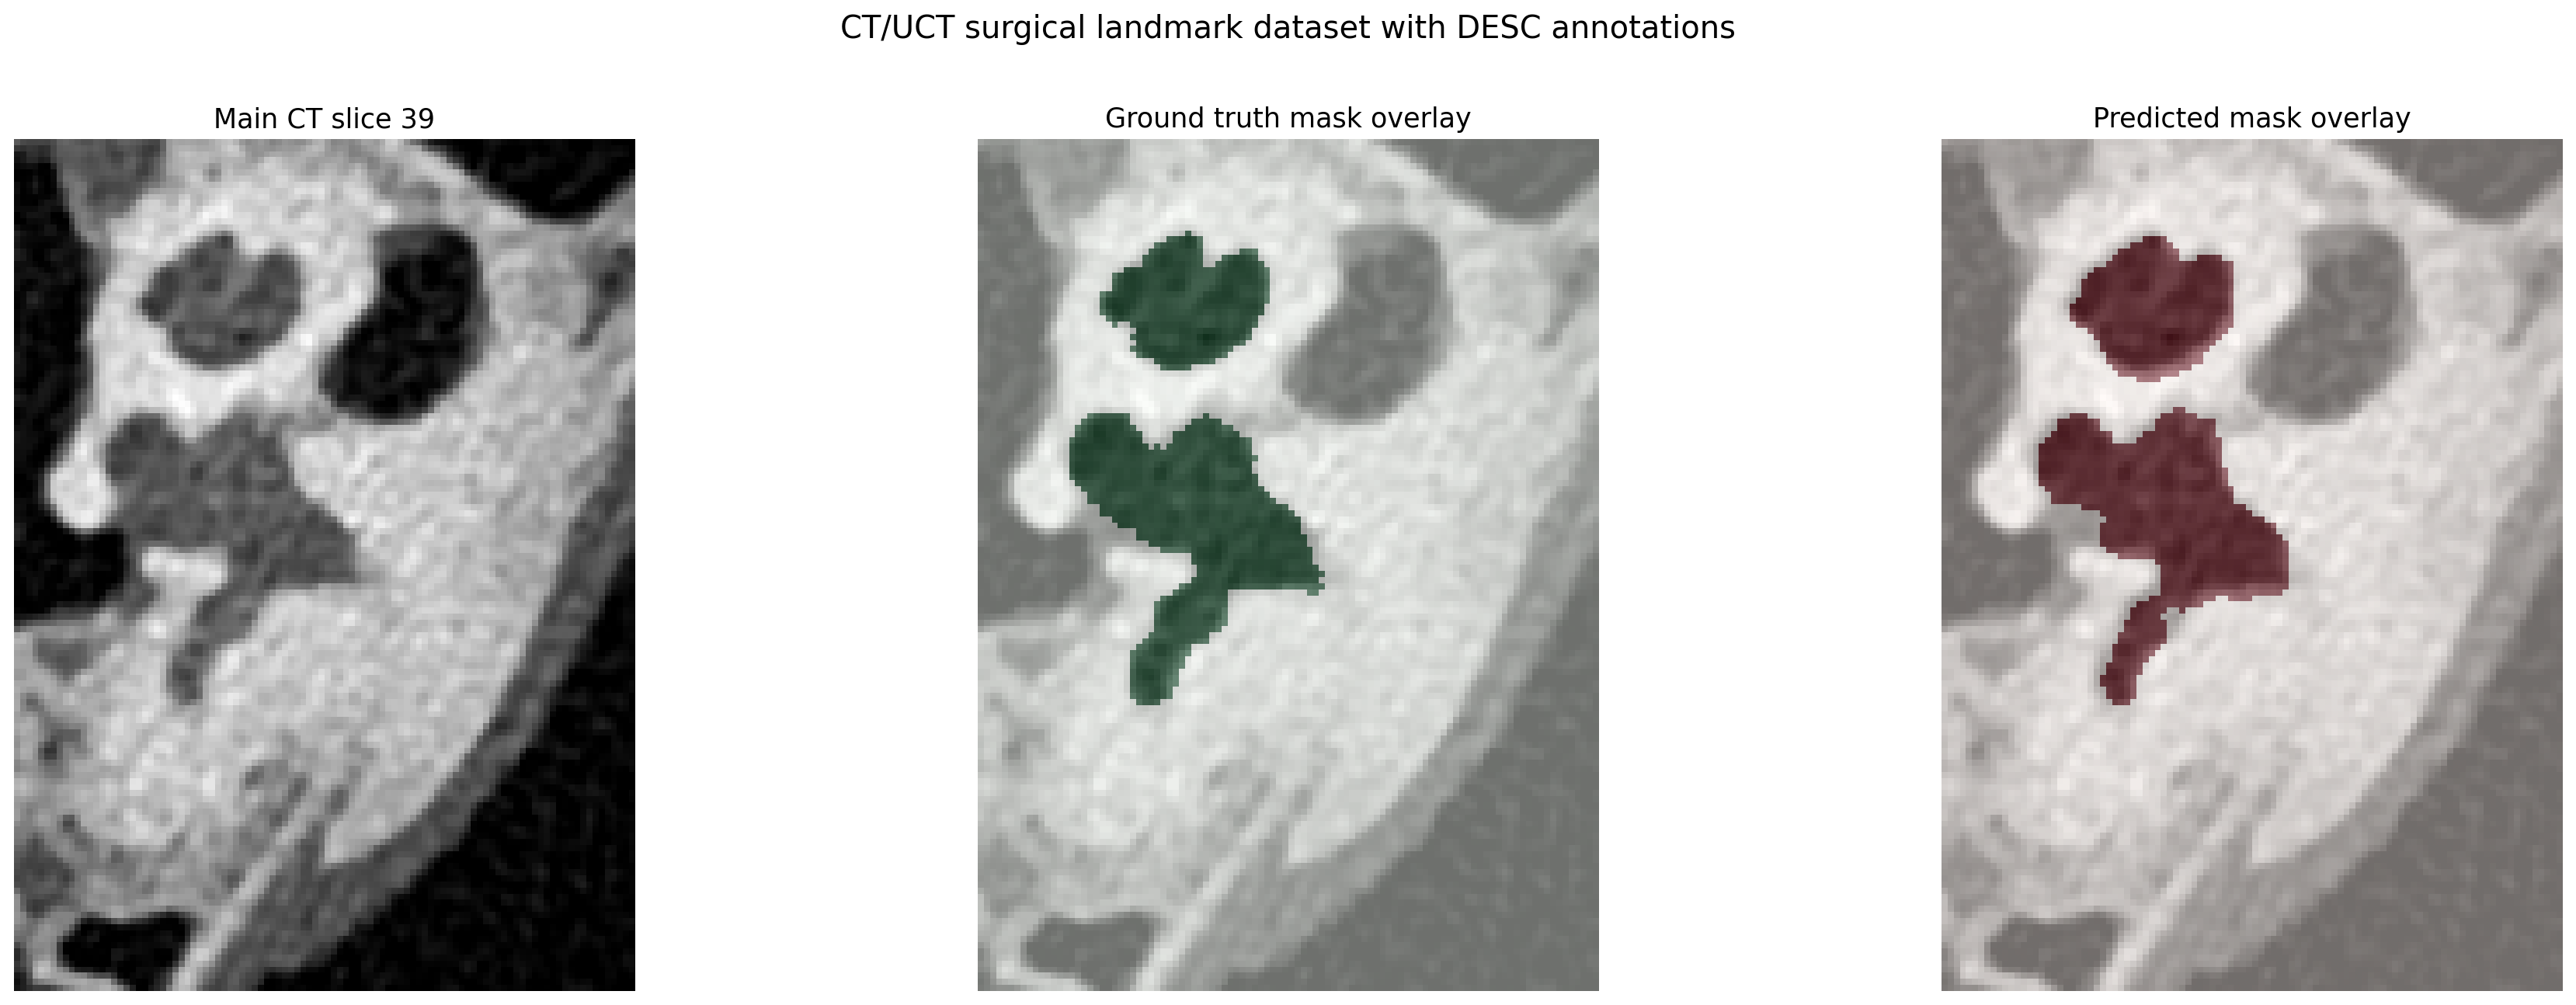

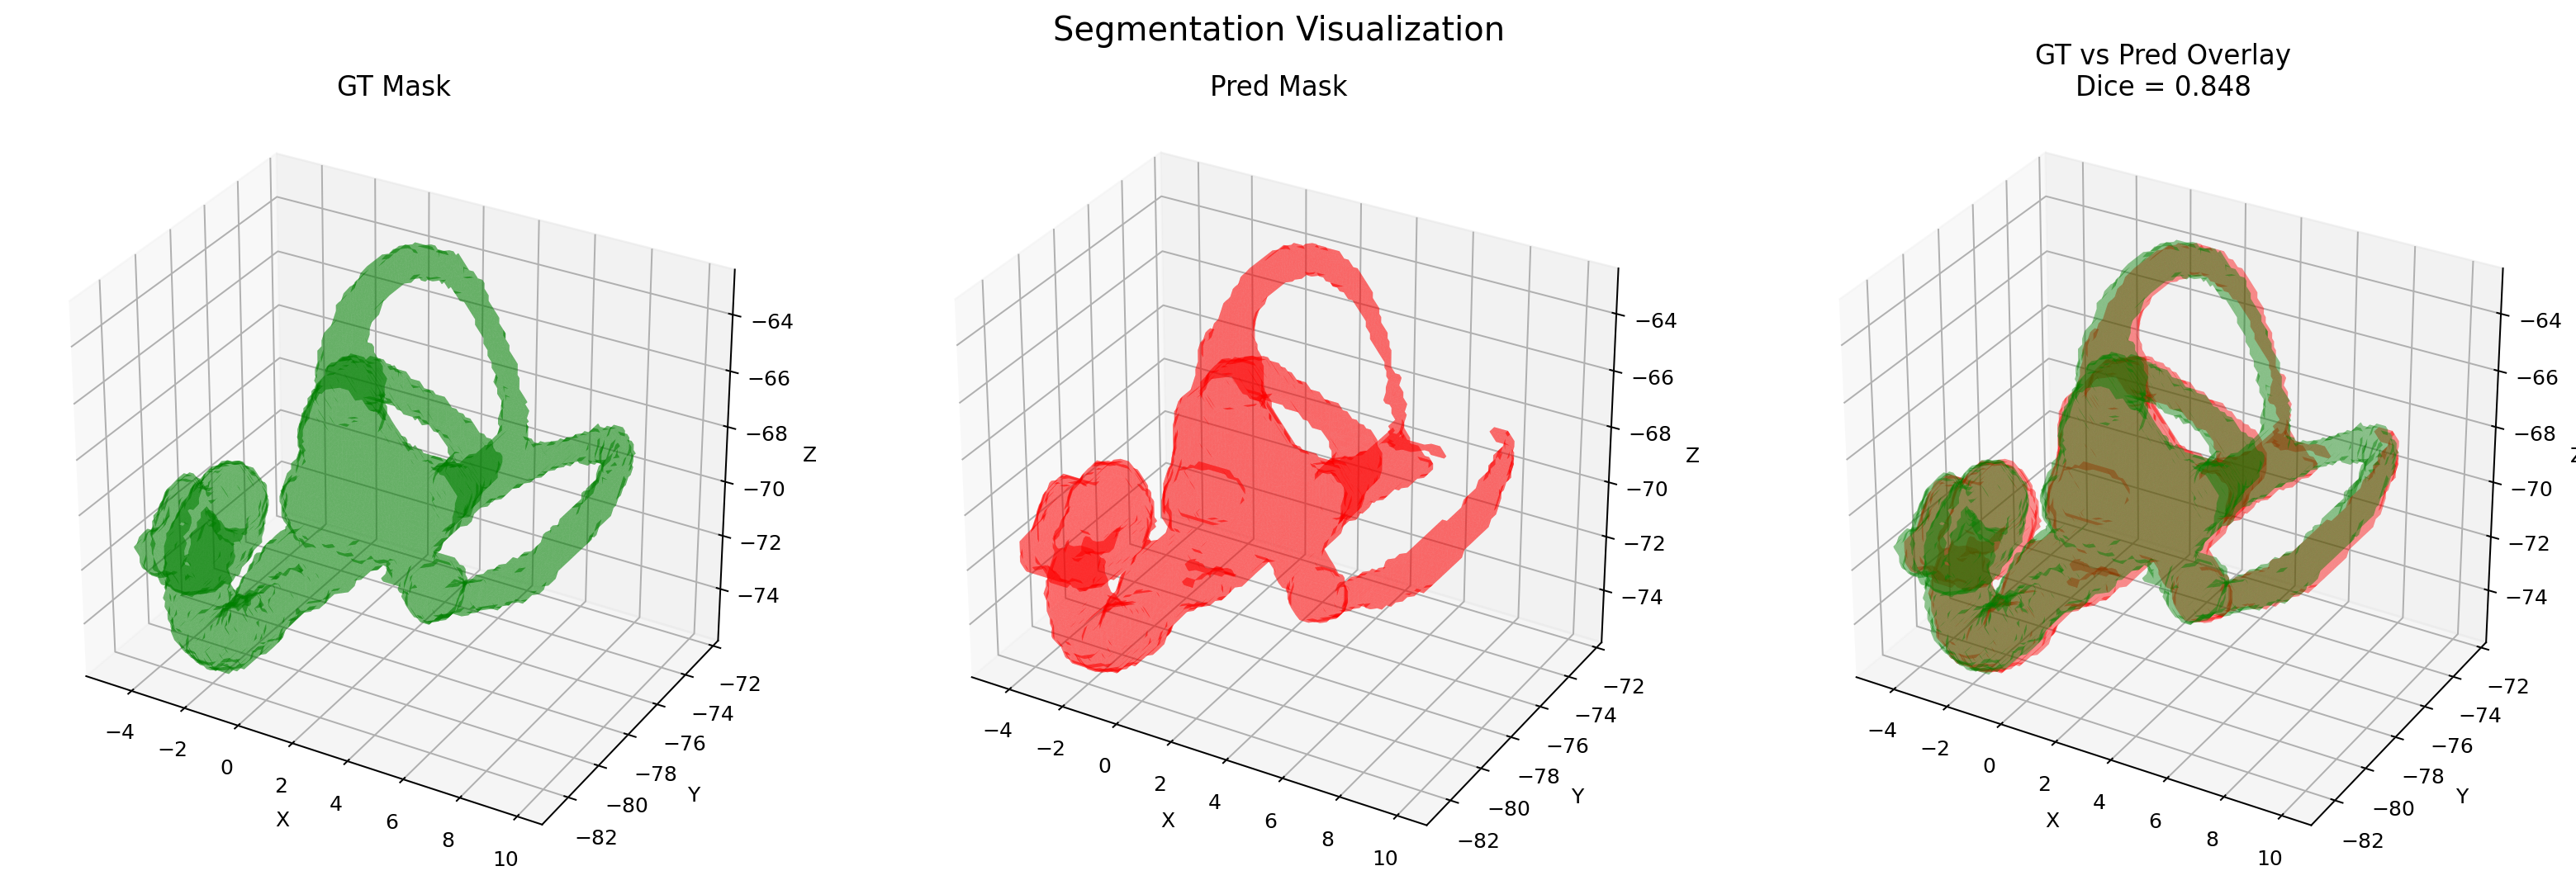

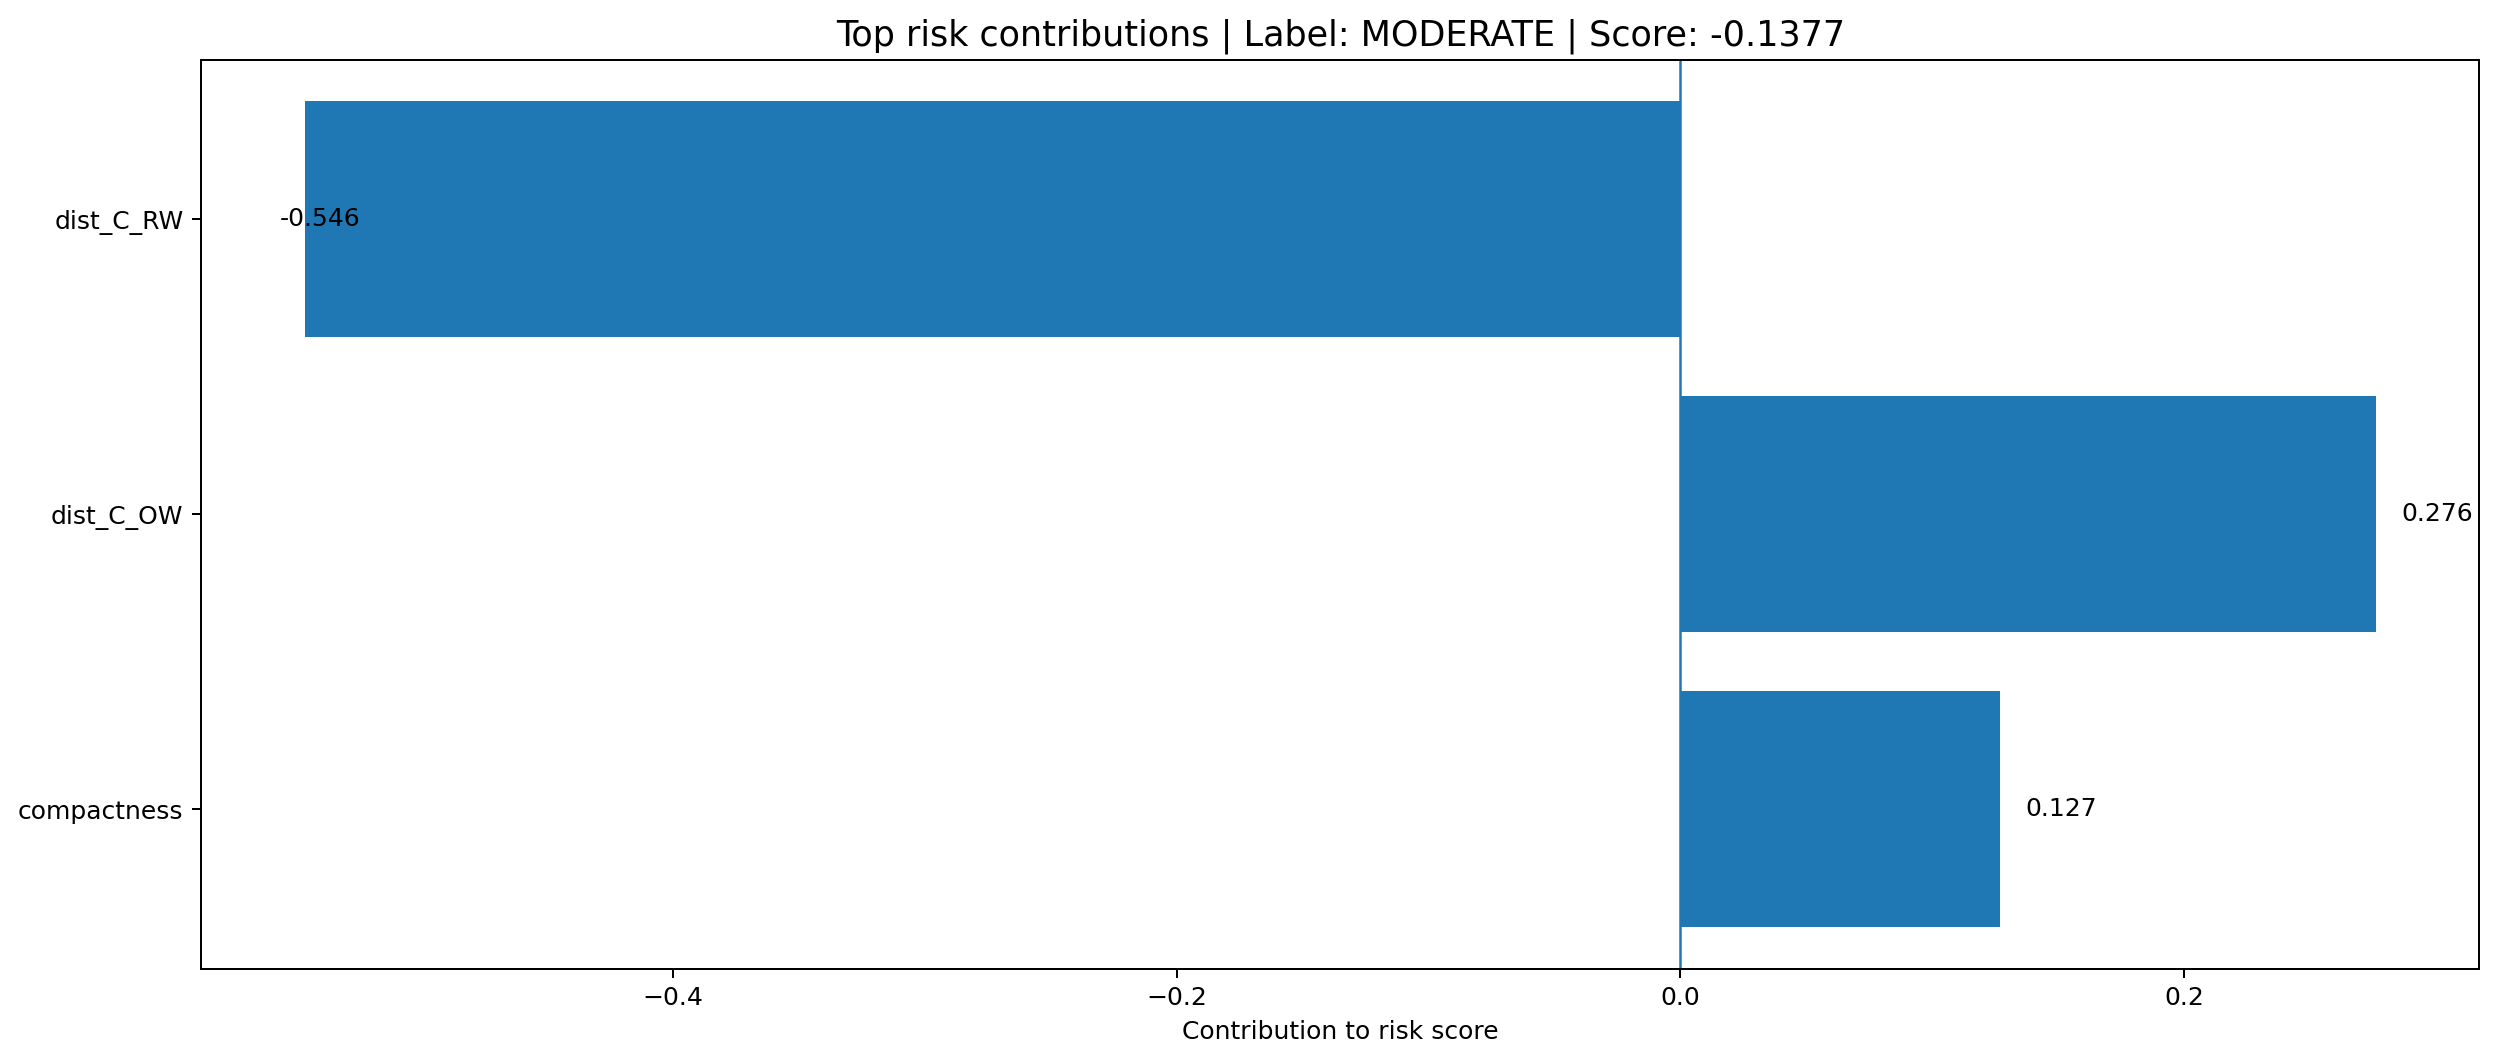


==================== FINAL REPORT ====================
CT file: T08_CT_RAW.nii
Risk output: MODERATE
Risk score: -0.1377

--- Predicted landmarks (world coordinates) ---
RW: [-0.70, -85.23, -72.99]
C: [1.52, -84.49, -71.72]
A: [-2.24, -84.12, -71.90]
OW: [2.20, -81.38, -63.93]
V: [1.35, -84.49, -71.72]

--- Concepts used for planning ---
dist_C_RW: 2.6654
dist_C_OW: 8.4100
dist_RW_OW: 10.2587
landmark_span: 10.2587
compactness: 0.0731
num_components: 1
volume_voxels: 35016
bbox_x: 101
bbox_y: 73
bbox_z: 65

--- Why this risk label? ---
- dist_C_RW decreases risk contribution by 0.546
- dist_C_OW increases risk contribution by 0.276
- compactness increases risk contribution by 0.127

--- Surgical recommendation ---
INTERMEDIATE ANATOMY: geometry is somewhat less typical. Review landmark spacing, segmentation quality, and the original CT before final planning.


In [50]:
# Result on the Notebook
result = run_full_pipeline_from_heatmaps(
    ct_path=sample["ct"],
    segmentation_model=segmentation_model,
    landmark_model=landmark_model,
    device=device,
    risk_profile=risk_profile,
    gt_mask_path=sample.get("mask", None),
    show=True
)

In [51]:
pdf_path = generate_case_report(
    sample=sample,
    result=result,
    out_pdf_path="reports/my_case_report.pdf",
    dataset_name=DATASET_NAME,
    show_in_notebook=True
)

print("Saved PDF:", pdf_path)


CASE REPORT SUMMARY
Project: CT-Based Cochlear Implant Surgical Planning Research Prototype
Dataset: CT/UCT surgical landmark dataset with DESC annotations
Subject: T08
Specimen ID: T08
Side: LEFT
Anatomical complexity: INTERMEDIATE ANATOMY
Planning score: -0.1377
Segmentation Dice: 0.8481

Why this label was assigned:
- dist_C_RW decreased the score by 0.546
- dist_C_OW increased the score by 0.276
- compactness increased the score by 0.127

Recommendation:
INTERMEDIATE ANATOMY: geometry is somewhat less typical. Review landmark spacing, segmentation quality, and the original CT before final planning.

PDF saved to: reports/my_case_report.pdf
Saved PDF: reports/my_case_report.pdf
